# Can machine learning pick NSE stocks? An honest test

**Data:** 10 years of daily prices (Jan 2016 – Oct 2026) for 54 large NSE stocks across
13 sectors, plus the NIFTY 50 index. 139,039 stock-day rows.

**Question:** using only price and volume history, can a model predict which stocks will
beat the median stock over the next week, and does that survive trading costs?

**Why "honest":** most stock-prediction tutorials report 80–95% accuracy. Those numbers
come from mistakes in how the model is tested, not from skill. This notebook shows the
mistake, removes it, and reports what is left.

The data is prepared by `run_pipeline.py`, the models are trained by `run_model.py`
(walk-forward, about 10 minutes). This notebook reads their saved outputs from the database.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import adjusted_rand_score, roc_auc_score
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import backtest, config, model, viz
from src.features import FEATURES
from src.load import read_sql

viz.apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

prices = read_sql("SELECT * FROM vw_daily", parse_dates=["date"])
raw = pd.read_csv(config.RAW_PRICES_FILE, parse_dates=["date"])
features = read_sql("SELECT * FROM fact_features", parse_dates=["date"])
predictions = read_sql("SELECT * FROM fact_predictions", parse_dates=["date"])
stocks = read_sql("SELECT * FROM dim_stock")
print(f"{len(prices):,} price rows | {prices['symbol'].nunique()} stocks | "
      f"{prices['date'].min():%d %b %Y} to {prices['date'].max():%d %b %Y}")
print(f"{len(features):,} feature rows | {len(predictions):,} out-of-sample predictions")

139,039 price rows | 54 stocks | 04 Jan 2016 to 01 Oct 2026
125,431 feature rows | 226,107 out-of-sample predictions


## 1. The data, and what had to be fixed

The project brief was a two-day sample table (1–2 October 2026) for these stocks. Two days
cannot train a model, and 2 October is a market holiday (Gandhi Jayanti), so the brief was
used as the **specification**: the same stocks, sectors and columns, filled with real
price history.

| Issue found | Scale | Treatment |
|---|---|---|
| Tickers in the brief no longer exist (TATAMOTORS, ZOMATO, LTIM) | 3 stocks | mapping table `universe.csv`: brief symbol → current ticker |
| Placeholder rows on market holidays (zero volume) | 653 rows | removed; the NIFTY 50 calendar defines a trading day |
| Demergers not adjusted by the data provider | 2 events | earlier prices back-adjusted (see chart) |
| Stocks listed after 2016 (JIOFIN, ZOMATO, HAL …) | 4 stocks | kept, with their real start date; no back-filling |
| Genuine extreme days (COVID crash, bank recapitalisation) | 18 moves above 25% | kept: they really happened |
| Splits and dividends | all stocks | all returns use the adjusted close |

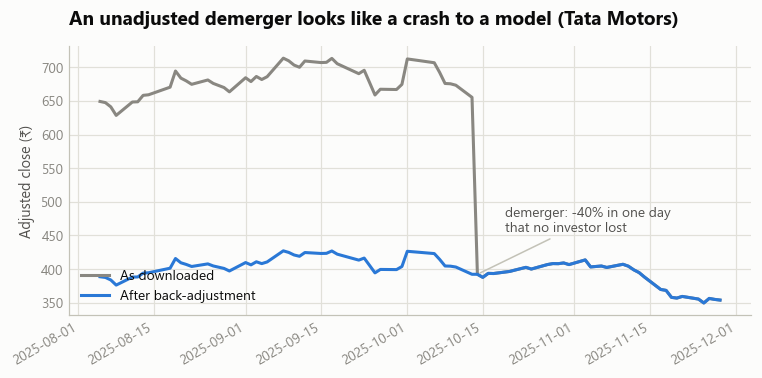

In [2]:
symbol, event_day = "TATAMOTORS", pd.Timestamp("2025-10-14")
window = (prices["symbol"] == symbol) & prices["date"].between(event_day - pd.Timedelta(days=70),
                                                               event_day + pd.Timedelta(days=45))
fixed = prices[window].set_index("date")["adj_close"]
ticker = stocks.loc[stocks["symbol"] == symbol, "yahoo_ticker"].item()
unfixed = raw[(raw["yahoo_ticker"] == ticker) & raw["date"].isin(fixed.index)].set_index("date")["adj_close"]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(unfixed.index, unfixed, color=viz.MUTED, label="As downloaded")
ax.plot(fixed.index, fixed, color=viz.BLUE, label="After back-adjustment")
ax.annotate(f"demerger: {unfixed.pct_change().loc[event_day]:+.0%} in one day\nthat no investor lost",
            xy=(event_day, unfixed.loc[event_day]), xytext=(18, 28), textcoords="offset points",
            fontsize=9, color=viz.INK_SECONDARY, arrowprops={"arrowstyle": "-", "color": viz.AXIS})
ax.set_ylabel("Adjusted close (₹)")
ax.set_title("An unadjusted demerger looks like a crash to a model (Tata Motors)")
ax.legend(loc="lower left")
fig.autofmt_xdate()
viz.save(fig, "01_demerger_adjustment")
plt.show()

**Why this matters.** Without the fix, the model would see a 40% one-day "loss", a huge
volatility spike and a new 52-week low for Tata Motors, all of which are artefacts. A
single bad row like this can dominate what a model learns about extreme moves.

## 2. Unsupervised learning: do stocks really move with their sector?

Before predicting anything, a sanity check on the sector labels. I cluster stocks using
only how their daily returns move together over the last three years (hierarchical
clustering on correlation distance) and compare the clusters with the official sectors.

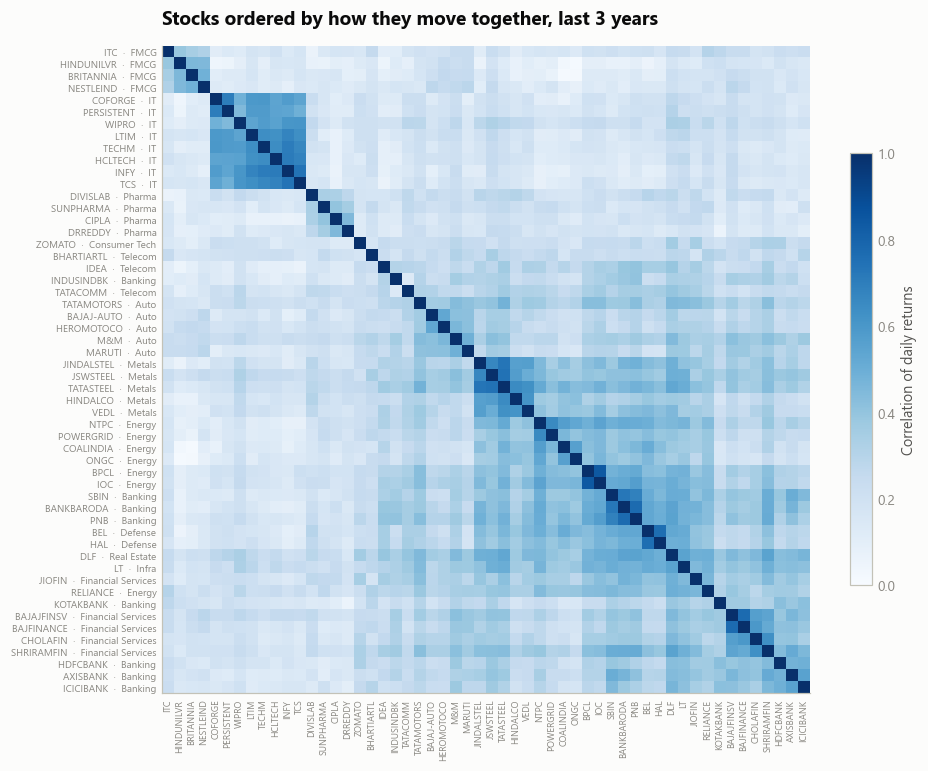

Stocks clustered: 54 | adjusted Rand index vs official sectors: 0.40 (1 = identical, 0 = random)
Average correlation: same sector 0.49, different sectors 0.25


cluster,1,2,3,4,5,6,7,8,9,10,11,12,13
sector,,,,,,,,,,,,,
Auto,0,0,0,0,0,0,0,5,0,0,0,0,0
Banking,0,0,0,0,0,0,1,0,3,4,0,0,0
Consumer Tech,0,0,0,0,0,0,0,0,0,0,0,0,1
Defense,0,0,0,0,0,0,0,0,2,0,0,0,0
Energy,0,0,0,0,0,0,0,0,7,0,0,0,0
FMCG,3,1,0,0,0,0,0,0,0,0,0,0,0
Financial Services,0,0,0,0,0,0,0,0,1,4,0,0,0
IT,0,0,8,0,0,0,0,0,0,0,0,0,0
Infra,0,0,0,0,0,0,0,0,1,0,0,0,0


In [3]:
recent = prices[prices["date"] > prices["date"].max() - pd.DateOffset(years=3)]
returns = recent.pivot(index="date", columns="symbol", values="ret_1d").dropna(axis=1, thresh=700).dropna()
corr = returns.corr()
distance = np.sqrt(0.5 * (1 - corr))                      # 0 = move together, 1 = move opposite
tree = linkage(squareform(distance.to_numpy(), checks=False), method="average")
order = leaves_list(tree)

sector_of = stocks.set_index("symbol")["sector"].reindex(corr.index)
clusters = fcluster(tree, t=sector_of.nunique(), criterion="maxclust")
ari = adjusted_rand_score(sector_of, clusters)

ordered = corr.iloc[order, order]
fig, ax = plt.subplots(figsize=(9.5, 8.5))
image = ax.imshow(ordered, cmap="Blues", vmin=0, vmax=1)
labels = [f"{s}  ·  {sector_of[s]}" for s in ordered.index]
ax.set_yticks(range(len(labels)), labels, fontsize=6.5)
ax.set_xticks(range(len(labels)), ordered.index, fontsize=6, rotation=90)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.6, label="Correlation of daily returns")
ax.set_title("Stocks ordered by how they move together, last 3 years")
viz.save(fig, "02_correlation_clusters")
plt.show()

within = np.mean([corr.loc[a, b] for a in corr.index for b in corr.index
                  if a < b and sector_of[a] == sector_of[b]])
across = np.mean([corr.loc[a, b] for a in corr.index for b in corr.index
                  if a < b and sector_of[a] != sector_of[b]])
print(f"Stocks clustered: {len(corr)} | adjusted Rand index vs official sectors: {ari:.2f} (1 = identical, 0 = random)")
print(f"Average correlation: same sector {within:.2f}, different sectors {across:.2f}")
cluster_table = pd.DataFrame({"sector": sector_of, "cluster": clusters})
pd.crosstab(cluster_table["sector"], cluster_table["cluster"])

**Finding.** Stocks in the same sector move together about twice as closely as stocks in different sectors (average correlation 0.49 vs 0.25). Clusters built from returns alone agree only partly with the official labels (adjusted Rand index 0.40). IT, Auto, FMCG and Pharma come out as clean groups. Energy, Metals, Defense, Infra, Real Estate and some public-sector banks merge into one large "cyclical" cluster: the market trades them as one theme, whatever the label says.

**Why it matters for the model.** Sector-relative features are meaningful for IT or Auto, and much less so for the cyclical block. It also means a "diversified" portfolio across those sectors is less diversified than it looks.

## 3. Framing the prediction problem

**Target.** For each stock and day: *will this stock's return over the next 5 trading days
be above the median stock's?* This is a relative target on purpose:
- it is balanced (50% ones) by construction, so accuracy cannot be faked by always saying "up";
- it removes the direction of the whole market, which nobody can predict from a chart.

**Features (17).** Momentum over several horizons, volatility, volume surge, RSI, MACD,
Bollinger position, distance from the 52-week high and low, trend (50-day vs 200-day
average), strength relative to the sector, and two market-regime features. Each
stock-level feature is converted to a rank across stocks on that day.

**No look-ahead.** Every feature uses data up to the day; only the target looks forward.

In [4]:
print("Target balance:", f"{features['target'].mean():.3f}")
features[FEATURES].describe().T[["mean", "std", "min", "max"]]

Target balance: 0.497


,mean,std,min,max
ret_1d,0.001,0.021,-0.351,0.462
ret_5d,0.004,0.047,-0.493,1.254
ret_20d,0.017,0.097,-0.739,1.857
ret_60d,0.051,0.174,-0.803,2.469
mom_12_1,0.220,0.431,-0.871,4.696
vol_20d,0.019,0.010,0.003,0.166
volume_ratio,1.014,0.651,0.000,15.939
rsi_14,52.456,12.336,7.611,93.670
macd_hist,0.000,0.007,-0.167,0.089
bb_pos,0.084,0.652,-2.070,2.087


## 4. Why tutorials report 90% accuracy: a leakage demonstration

The usual tutorial shuffles all rows and splits them 80/20. With daily stock data this
is a serious error. The row for Monday and the row for Tuesday of the same stock have
almost the same features, and their 5-day targets share four of five days. A shuffled
split puts one in train and the other in test, so the model is "tested" on answers it has
effectively already seen.

Below, the **same model on the same data** is evaluated both ways.

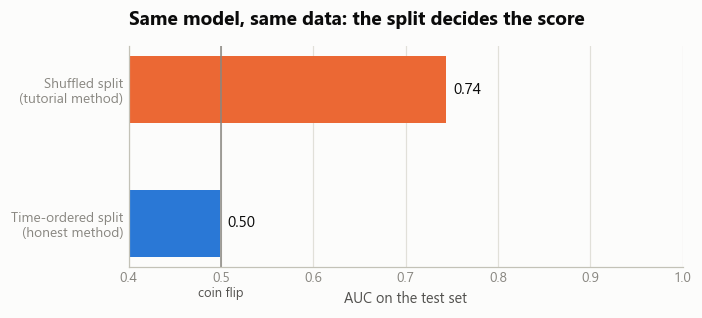

AUC shuffled: 0.743 | AUC time-ordered: 0.498


In [5]:
demo = model.prepare(features).dropna(subset=["target"])
demo = demo[demo["date"] >= "2021-01-01"]
x, y = demo[FEATURES], demo["target"].astype(int)
flexible = lambda: RandomForestClassifier(n_estimators=60, min_samples_leaf=1, n_jobs=-1,
                                          random_state=config.RANDOM_STATE)

# (a) the tutorial way: shuffle rows
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, shuffle=True, random_state=config.RANDOM_STATE)
auc_shuffled = roc_auc_score(y_te, flexible().fit(x_tr, y_tr).predict_proba(x_te)[:, 1])

# (b) the honest way: train on the past, test on the future, with a gap
dates = np.sort(demo["date"].unique())
cut = int(len(dates) * 0.8)
train_mask = demo["date"] <= dates[cut - config.HORIZON - 1]
test_mask = demo["date"] >= dates[cut]
auc_time = roc_auc_score(y[test_mask], flexible().fit(x[train_mask], y[train_mask]).predict_proba(x[test_mask])[:, 1])

fig, ax = plt.subplots(figsize=(6.5, 2.6))
bars = ax.barh(["Shuffled split\n(tutorial method)", "Time-ordered split\n(honest method)"],
               [auc_shuffled, auc_time], color=[viz.ORANGE, viz.BLUE], height=0.5)
for bar, value in zip(bars, [auc_shuffled, auc_time]):
    ax.text(value + 0.008, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", fontsize=10)
ax.axvline(0.5, color=viz.MUTED, linewidth=1)
ax.text(0.5, 1.55, "coin flip", ha="center", fontsize=8.5, color=viz.INK_SECONDARY)
ax.set_xlim(0.4, 1.0)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC on the test set")
ax.set_title("Same model, same data: the split decides the score")
viz.save(fig, "03_leakage_demo")
plt.show()
print(f"AUC shuffled: {auc_shuffled:.3f} | AUC time-ordered: {auc_time:.3f}")

**Finding.** With a shuffled split the model scores an AUC of **0.74**, which looks like a strong, tradeable model. With a time-ordered split the same model scores **0.50**: a coin flip. Nothing changed except how the test set was chosen. The 0.74 is the model recognising near-duplicate neighbouring days, not predicting the future.

Everything from here on uses time-ordered validation only.

## 5. Walk-forward results

Each test year from 2021 is predicted by models trained only on earlier years, with a
5-day gap between train and test. Three models, from simple to flexible, so that any gain
from complexity is visible.

- **AUC**: 0.5 is a coin flip.
- **Information coefficient (IC)**: daily rank correlation between prediction and realised
  return. The t-statistic uses non-overlapping weeks.
- **Top-10 hit rate**: share of the 10 highest-ranked stocks that beat the median.

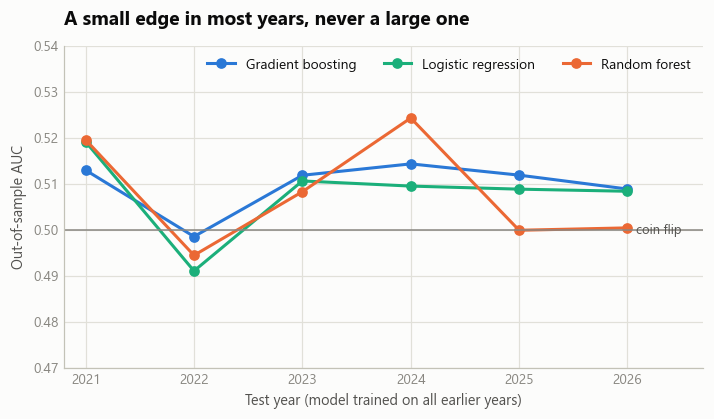

,model,rows,auc,accuracy,top_k_hit_rate,mean_ic,ic_t_stat
0,Gradient boosting,75099,0.510,0.505,0.514,0.019,0.784
1,Random forest,75099,0.508,0.508,0.504,0.015,0.486
2,Logistic regression,75099,0.508,0.507,0.509,0.018,1.243


In [6]:
metrics = model.evaluate(predictions)
by_year = model.evaluate_by_year(predictions)
best = metrics.loc[0, "model"]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, grp in by_year.groupby("model"):
    ax.plot(grp["test_year"], grp["auc"], marker="o", color=viz.MODEL_COLORS[name], label=name)
ax.axhline(0.5, color=viz.MUTED, linewidth=1)
ax.text(by_year["test_year"].max() + 0.08, 0.5, "coin flip", va="center", fontsize=8.5, color=viz.INK_SECONDARY)
ax.set_ylim(0.47, 0.54)
ax.set_xlim(by_year["test_year"].min() - 0.2, by_year["test_year"].max() + 0.7)
ax.set_xticks(sorted(by_year["test_year"].unique()))
ax.set_xlabel("Test year (model trained on all earlier years)")
ax.set_ylabel("Out-of-sample AUC")
ax.set_title("A small edge in most years, never a large one")
ax.legend(loc="upper right", ncol=3)
viz.save(fig, "04_auc_by_year")
plt.show()
metrics

**Finding.** All three models land at an AUC of about **0.51**, above 0.5 in five of six years (2022 is the exception). The information coefficient is about 0.02 with t-statistics between 0.5 and 1.2, so the edge is **not statistically significant**. Gradient boosting is marginally best; the simple logistic regression is almost as good, so model complexity adds very little. That pattern, where every model finds the same tiny signal, is what a weakly predictable target looks like.

## 6. Backtest: does the edge make money?

A prediction score is not a business result. The strategy: every week buy the 10 stocks
with the highest predicted probability, equal weights, hold one week. A cost of 0.10% is
charged on every buy and every sell. The benchmark holds all stocks in equal weights, so
the only difference is stock selection.

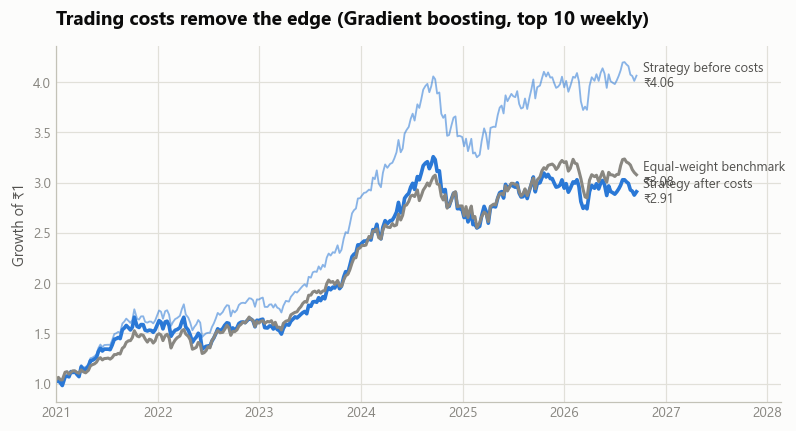

{'weeks': 283.0, 'mean_weekly_excess': -0.0001, 't_stat': -0.1589, 'weeks_beating_benchmark': 0.4806, 'avg_turnover': 0.5929}


,annual_return,annual_volatility,sharpe,max_drawdown,total_return
Strategy (after costs),20.9%,18.3%,1.13,-21.8%,191%
Strategy (before costs),28.4%,18.2%,1.46,-19.8%,306%
Equal-weight benchmark,22.2%,15.5%,1.37,-17.0%,208%


In [7]:
weekly = backtest.run_backtest(predictions, best)
summary = backtest.summarise(weekly)
test = backtest.excess_return_test(weekly)

growth = pd.DataFrame({
    "Strategy before costs": (1 + weekly["gross_return"]).cumprod(),
    "Strategy after costs": (1 + weekly["strategy_return"]).cumprod(),
    "Equal-weight benchmark": (1 + weekly["benchmark_return"]).cumprod(),
}).set_index(weekly["date"])

fig, ax = plt.subplots(figsize=(8.5, 4.2))
styles = {"Strategy before costs": (viz.BLUE, 1.2), "Strategy after costs": (viz.BLUE, 2.4),
          "Equal-weight benchmark": (viz.MUTED, 2.0)}
for name, (color, width) in styles.items():
    ax.plot(growth.index, growth[name], color=color, linewidth=width,
            alpha=0.55 if name == "Strategy before costs" else 1)
    ax.text(growth.index[-1] + pd.Timedelta(days=25), growth[name].iloc[-1],
            f"{name}\n₹{growth[name].iloc[-1]:.2f}", va="center", fontsize=8.5, color=viz.INK_SECONDARY)
ax.set_xlim(growth.index[0], growth.index[-1] + pd.Timedelta(days=520))
ax.set_ylabel("Growth of ₹1")
ax.set_title(f"Trading costs remove the edge ({best}, top 10 weekly)")
viz.save(fig, "05_equity_curve")
plt.show()

print({k: round(float(v), 4) for k, v in test.items()})
summary.style.format({"annual_return": "{:.1%}", "annual_volatility": "{:.1%}", "sharpe": "{:.2f}",
                      "max_drawdown": "{:.1%}", "total_return": "{:.0%}"})

**Finding.** Before costs the strategy returns **28.4% a year** against **22.2%** for the benchmark. After costs it returns **20.9%**, slightly *below* the benchmark, with higher volatility and a deeper drawdown (Sharpe 1.13 vs 1.37). It beats the benchmark in 48% of weeks and the weekly excess return is not different from zero (t = -0.16).

The reason is turnover: the model replaces about 59% of the portfolio every week, and those trades cost more than the edge is worth.

## 7. Skill or luck? And how much cost can the strategy bear?

**Luck test.** 1,000 portfolios that pick 10 stocks at random every week show the range of
outcomes with no skill at all. Compared before costs on both sides.

**Cost sensitivity.** The same backtest at different cost levels gives the break-even cost.

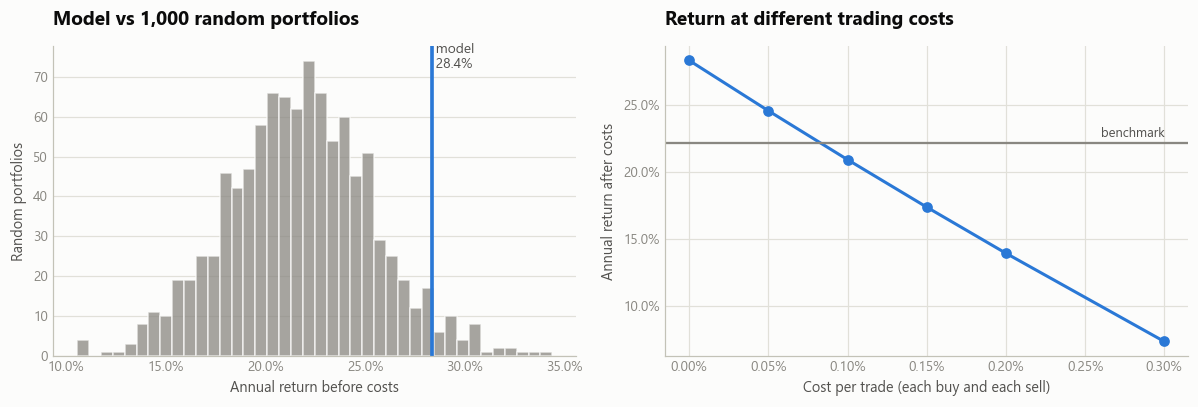

Model beats 96% of random portfolios (before costs)
Break-even cost per trade: 0.083% | average weekly turnover: 59%


In [8]:
random_returns = backtest.random_portfolios(predictions, best)
gross_annual = summary.loc["Strategy (before costs)", "annual_return"]
benchmark_annual = summary.loc["Equal-weight benchmark", "annual_return"]
percentile = (random_returns < gross_annual).mean()

cost_levels = [0, 0.0005, 0.001, 0.0015, 0.002, 0.003]
cost_curve = pd.Series({c: backtest.performance(backtest.run_backtest(predictions, best, cost=c)["strategy_return"])["annual_return"]
                        for c in cost_levels})
breakeven = np.interp(benchmark_annual, cost_curve.to_numpy()[::-1], cost_curve.index.to_numpy()[::-1])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.hist(random_returns * 100, bins=40, color=viz.MUTED, alpha=0.75, edgecolor=viz.SURFACE)
ax.axvline(gross_annual * 100, color=viz.BLUE, linewidth=2.4)
ax.text(gross_annual * 100, ax.get_ylim()[1] * 0.93, f" model\n {gross_annual:.1%}", color=viz.INK_SECONDARY, fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("Annual return before costs")
ax.set_ylabel("Random portfolios")
ax.grid(axis="x", visible=False)
ax.set_title("Model vs 1,000 random portfolios")

ax = axes[1]
ax.plot(cost_curve.index * 100, cost_curve * 100, marker="o", color=viz.BLUE)
ax.axhline(benchmark_annual * 100, color=viz.MUTED, linewidth=1.5)
ax.text(cost_curve.index[-1] * 100, benchmark_annual * 100 + 0.5, "benchmark", ha="right", fontsize=8.5, color=viz.INK_SECONDARY)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=2))
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("Cost per trade (each buy and each sell)")
ax.set_ylabel("Annual return after costs")
ax.set_title("Return at different trading costs")
fig.tight_layout()
viz.save(fig, "06_luck_and_costs")
plt.show()

print(f"Model beats {percentile:.0%} of random portfolios (before costs)")
print(f"Break-even cost per trade: {breakeven:.3%} | average weekly turnover: {test['avg_turnover']:.0%}")

**Finding.** Before costs the model beats **96% of random portfolios**, so the signal is probably real, although short of the usual 97.5% bar. But the strategy only matches the benchmark if each trade costs less than about **0.08%**. A realistic all-in cost for a retail investor in India (brokerage, STT, stamp duty, exchange fees, slippage) is higher than that.

**So the signal exists and is too small to trade weekly.**

## 8. What the model learned

Permutation importance on the most recent test data (2025–2026): shuffle one feature and
measure how much the AUC falls. Unlike built-in tree importance, this is measured on
unseen data, so a feature only scores if it actually helps out of sample.

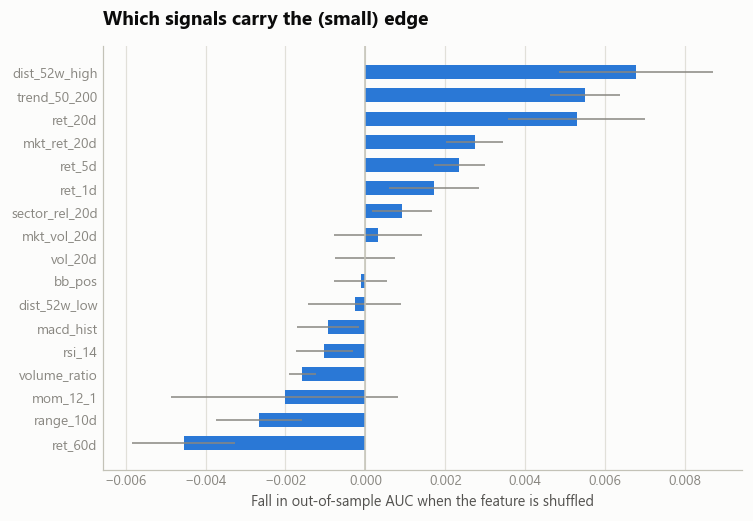

,importance,std
dist_52w_high,0.007,0.002
trend_50_200,0.005,0.001
ret_20d,0.005,0.002
mkt_ret_20d,0.003,0.001
ret_5d,0.002,0.001
ret_1d,0.002,0.001
sector_rel_20d,0.001,0.001
mkt_vol_20d,0.000,0.001


In [9]:
prepared = model.prepare(features).dropna(subset=["target"])
train_end = prepared.loc[prepared["date"] < "2025-01-01", "date"].unique()
train_end = np.sort(train_end)[-config.HORIZON - 1]
fit_rows = prepared["date"] <= train_end
recent_rows = prepared["date"] >= "2025-01-01"

explainer = model.make_models()["Gradient boosting"].fit(prepared.loc[fit_rows, FEATURES],
                                                         prepared.loc[fit_rows, "target"].astype(int))
importance = permutation_importance(explainer, prepared.loc[recent_rows, FEATURES],
                                    prepared.loc[recent_rows, "target"].astype(int),
                                    scoring="roc_auc", n_repeats=5, random_state=config.RANDOM_STATE)
ranking = pd.DataFrame({"importance": importance.importances_mean, "std": importance.importances_std},
                       index=FEATURES).sort_values("importance")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(ranking.index, ranking["importance"], xerr=ranking["std"], color=viz.BLUE, height=0.6,
        error_kw={"ecolor": viz.MUTED, "elinewidth": 1})
ax.axvline(0, color=viz.AXIS, linewidth=1)
ax.set_xlabel("Fall in out-of-sample AUC when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Which signals carry the (small) edge")
viz.save(fig, "07_feature_importance")
plt.show()
ranking.sort_values("importance", ascending=False).head(8)

**Finding.** The edge comes from **trend and momentum**: distance from the 52-week high, the 50/200-day trend and 20-day return are the top three. Short-term oscillators that dominate trading tutorials (RSI, MACD, Bollinger position) contribute almost nothing out of sample. Even the best feature moves the AUC by less than 0.01, which is consistent with the small overall edge.

## Conclusions

| # | Conclusion | Evidence |
|---|---|---|
| 1 | **Price-based ML has a small, real-looking edge on large NSE stocks, and it is not tradeable weekly.** | AUC 0.51; 28.4% vs 22.2% before costs; 20.9% vs 22.2% after costs |
| 2 | **Validation method matters more than the model.** | Same model: AUC 0.74 with a shuffled split, 0.50 with a time split |
| 3 | **Simple models are enough.** | Logistic regression AUC 0.508 vs gradient boosting 0.510 |
| 4 | **Momentum and trend carry the signal; popular oscillators do not.** | Permutation importance on 2025-26 data |
| 5 | **Data cleaning decides what the model learns.** | Two unadjusted demergers would have added fake crashes of -40% and -65% |

### What I would do next
- **Cut turnover**: hold positions longer, or only trade when the ranking changes a lot. The break-even cost shows turnover is the binding problem, not prediction.
- **Add information that is not in the price**: earnings dates, delivery percentage, FII/DII flows.
- **Predict risk instead of return**: volatility is far more predictable than direction.

### Limitations
- **Survivorship bias.** The 54 stocks are today's large companies. Firms that shrank or were delisted are missing, so all returns here (strategy *and* benchmark) are higher than an investor could have earned.
- **One provider, adjusted prices.** Two corporate actions needed manual correction; others may remain.
- **Costs are a flat assumption**; real costs depend on order size and liquidity.
- **Sensitive to the rebalance day.** Shifting the weekly schedule by a day changes annual returns by about a percentage point.
- **No tuning.** Hyperparameters were set once and not optimised on the test years. Tuning on them would have improved the numbers and made them meaningless.
- This is an analysis project, not investment advice.